In [ ]:
#| hide 
from SFCmodeler.term import Term, Variable, Parameter
from SFCmodeler.SFCmodel import SFCmodel
from SFCmodeler.modelresults import ModelResults


# SFCmodeler

> A lightweight Python solver for Post-Keynesian Stock-Flow Consistent (SFC) or other time-series models, built on top of Pandas and Sympy.

## Usage

### Installation

```sh
$ pip install SFCmodeler
```
(Doesn't work yet :)

Install latest from the GitHub [repository][repo]:

```sh
$ pip install git+https://github.com/slevey087/SFCmodeler.git
```

[repo]: https://github.com/slevey087/SFCmodeler
[docs]: https://slevey087.github.io/SFCmodeler/
[pypi]: https://pypi.org/project/SFCmodeler/
[conda]: https://anaconda.org/slevey087/SFCmodeler

Then import with 
```py
from SFCmodeler import *
```

### Documentation

Documentation can be found hosted on this GitHub [repository][repo]'s [pages][docs]. Additionally you can find package manager specific guidelines on [conda][conda] and [pypi][pypi] respectively.

[repo]: https://github.com/slevey087/SFCmodeler
[docs]: https://slevey087.github.io/SFCmodeler/
[pypi]: https://pypi.org/project/SFCmodeler/
[conda]: https://anaconda.org/slevey087/SFCmodeler

## How to use

First declare `Parameter`s (fixed exogenous values) and `Variable`s (found endogenously by the solver), each with a `name`, and optional `description` and `initial_value`

In [ ]:
Variable.default_value = 10  # This sets a default initial value for Variables

C = Variable("C","Consumption")
T = Variable("T","Taxes")
V = Variable("V","Wealth",100)   # The number 100 overrides the default value declared above
Y = Variable("Y","GDP")

alpha1 = Parameter("alpha_1","MPC out of income",0.6)
alpha2 = Parameter("alpha_2","MPC out of wealth",0.4)
G = Parameter("G","Government spending",5)
theta = Parameter("theta","Tax rate",0.2)

Next define the `SFCmodel` with a list of equations. Each equation should have one variable on the LHS, then `<<` as the equals sign, then any valid `Sympy` expression:

In [ ]:
model = SFCmodel(
    [
        C << alpha1 * (Y - T) + alpha2 * V(-1),
        Y << C + G,
        T << theta * Y,
        V << V(-1) + Y - T - C
    ]
)

Run `.solve()` to solve one period forward, or specify a number of periods to solve more than one time step, and then manipulate the results using `.data`:

In [ ]:
model.solve(10)

model.data

  0%|          | 0/11 [00:00<?, ?it/s]

|      |     $C$ |   $G$ |      $T$ |      $V$ |   $V_{-1}$ |     $Y$ |   $\alpha_{1}$ |   $\alpha_{2}$ |   $\theta$ |
|:-----|--------:|------:|---------:|---------:|-----------:|--------:|---------------:|---------------:|-----------:|
| 2000 | 10      |     5 | 10       | 100      |   100      | 10      |            0.6 |            0.4 |        0.2 |
| 2001 | 81.5385 |     5 | 17.3077  |  87.6923 |   100      | 86.5385 |            0.6 |            0.4 |        0.2 |
| 2002 | 72.071  |     5 | 15.4142  |  77.2781 |    87.6923 | 77.071  |            0.6 |            0.4 |        0.2 |
| 2003 | 64.0601 |     5 | 13.812   |  68.4661 |    77.2781 | 69.0601 |            0.6 |            0.4 |        0.2 |
| 2004 | 57.2816 |     5 | 12.4563  |  61.0098 |    68.4661 | 62.2816 |            0.6 |            0.4 |        0.2 |
| 2005 | 51.546  |     5 | 11.3092  |  54.7006 |    61.0098 | 56.546  |            0.6 |            0.4 |        0.2 |
| 2006 | 46.6927 |     5 | 10.3385  |  49.362  |    54.7006 | 51.6927 |            0.6 |            0.4 |        0.2 |
| 2007 | 42.5862 |     5 |  9.51723 |  44.8448 |    49.362  | 47.5862 |            0.6 |            0.4 |        0.2 |
| 2008 | 39.1114 |     5 |  8.82228 |  41.0225 |    44.8448 | 44.1114 |            0.6 |            0.4 |        0.2 |
| 2009 | 36.1712 |     5 |  8.23423 |  37.7883 |    41.0225 | 41.1712 |            0.6 |            0.4 |        0.2 |
| 2010 | 33.6833 |     5 |  7.73666 |  35.0516 |    37.7883 | 38.6833 |            0.6 |            0.4 |        0.2 |

`.data` returns a `ModelResults` object, which is a fancy pandas `DataFrame` such that you can use your parameters and variables as indexers, or also calculated expressions, and also quickly plot:

<Axes: >

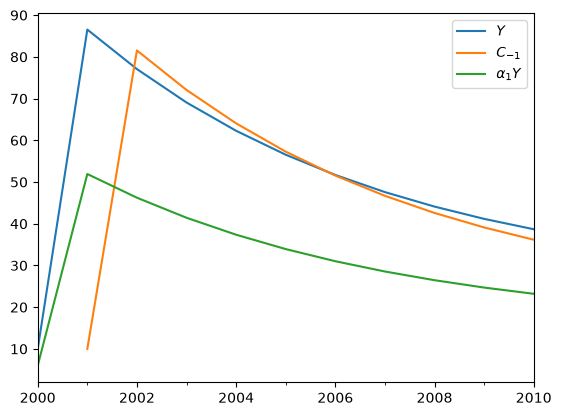

In [ ]:
model.data[[Y,C(-1),alpha1*Y]].plot()

See the other doc pages for more details and additional features.